# 2. Model training and evaluation

This notebook trains the **retention model** and shows how it is evaluated. It uses the event and feature datasets written by the event pipeline (notebook 1) for every match.

## What is being modelled

**Expected retention (xR)** is the chance that an *average* striker keeps the ball, given the situation: how hard the pass was, the pressure on him, the support around him, and his own movement and position against the back line. The model is the **average of two models**:

* a **logistic regression** (median imputation, standardised inputs, L2 penalty `C = 0.5`), which is stable with only about 500 hold-ups;
* a small **boosted-tree model** (LightGBM: 150 trees, learning rate 0.03, 4 leaves, at least 25 hold-ups per leaf), which can capture interactions.

It is trained on the situation at **first contact**. Applying the same fitted model to the situation at **pass release** gives the odds the striker *inherited*. That splits what he achieved into two parts:

* **set-up added** = xR at contact - xR at release (what his movement before the ball arrived changed), centred on the league mean;
* **duel added** = kept - xR at contact (what he did once the ball arrived);
* **retention over expected (RoE)** = kept - xR at release = set-up added + duel added (after centring).

## How it is evaluated

With about 500 hold-ups from 20 matches, a model scored on data it was trained on would look far better than it is. Every prediction below is **out of fold**: matches are split into 10 groups, a model is trained on 9 and scores the 10th, so no hold-up is ever scored by a model that saw its match. The random fold assignment is repeated 5 times and the predictions averaged.

In [1]:
import sys
sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from holdup import model
from holdup.pipelines import run_training_pipeline, read_datasets
from holdup.paths import EVENTS_DIR, FEATURES_DIR, MODEL_PATH
from holdup.plots import plot_calibration, plot_waterfall, clean_axes, BLUE, ORANGE, GREEN, RED, GREY
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

events = read_datasets(EVENTS_DIR); features = read_datasets(FEATURES_DIR)
print(len(events), 'hold-ups from', events.match_id.nunique(), 'matches;', int(events.retained.notna().sum()), 'with a kept / lost outcome (own shots are not scored)')

535 hold-ups from 20 matches; 521 with a kept / lost outcome (own shots are not scored)


## 1. Train

`run_training_pipeline()` does everything in this notebook in one call: it calibrates expected pass completion, cross-validates the models, fits the final models on all hold-ups and saves them to `data/models/holdup_model.joblib`. The sections below look at what it produced.

In [2]:
trained = run_training_pipeline()      # about a minute
summary, data, table = trained['summary'], trained['data'], trained['table']
print(f"{summary['n_training']} training hold-ups from {summary['n_matches']} matches; observed retention {summary['base_rate']:.1%}")
print('saved to', MODEL_PATH)

521 training hold-ups from 20 matches; observed retention 40.5%
saved to C:\Users\zcoch\Skill Corner Hold Up Play Model\data\models\holdup_model.joblib


## 2. Expected pass completion (a model input)

The physics value from notebook 1 (`xpass_raw`) says whether a defender could get to the ball, but it is not a probability: on average it is far lower than the share of passes that complete. It is turned into one with a two-number logistic fit (**Platt calibration**) against whether the pass was received or intercepted. The fit is done out of fold by match, so each pass is calibrated by a fit that never saw its match. The final calibration is stored with the model.

532 passes; 64.8% completed; mean raw physics value 0.30, mean calibrated 0.65
AUC for completed vs intercepted: raw 0.733, calibrated 0.725


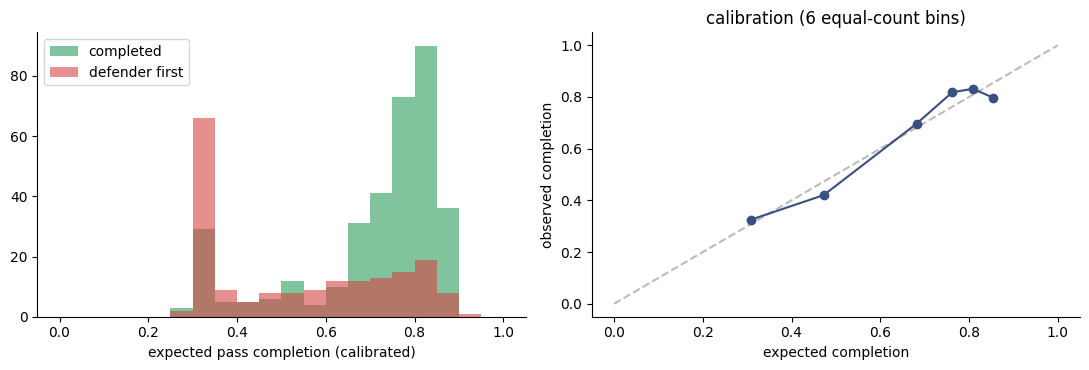

Platt coefficients saved with the model (slope, intercept): [0.315 1.384]


In [3]:
x = table.dropna(subset=['xpass_raw']).copy()
x['completed'] = (x.outcome == 'received').astype(int)
print(f"{len(x)} passes; {x.completed.mean():.1%} completed; mean raw physics value {x.xpass_raw.mean():.2f}, mean calibrated {x.xpass.mean():.2f}")
print(f"AUC for completed vs intercepted: raw {roc_auc_score(x.completed, x.xpass_raw):.3f}, calibrated {roc_auc_score(x.completed, x.xpass):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, c, lab in ((1, GREEN, 'completed'), (0, RED, 'defender first')):
    ax[0].hist(x[x.completed == k].xpass, bins=np.linspace(0, 1, 21), alpha=.6, color=c, label=lab)
ax[0].set_xlabel('expected pass completion (calibrated)'); ax[0].legend(); clean_axes(ax[0])
c = model.calibration_table(x.completed, x.xpass, 6)
ax[1].plot([0, 1], [0, 1], c='#bbb', ls='--'); ax[1].plot(c.predicted, c.observed, 'o-', c=BLUE)
ax[1].set_xlabel('expected completion'); ax[1].set_ylabel('observed completion'); ax[1].set_title('calibration (6 equal-count bins)'); clean_axes(ax[1])
plt.tight_layout(); plt.show()
print('Platt coefficients saved with the model (slope, intercept):', np.round(trained['model']['xpass_platt'], 3))

## 3. The feature table

Thirteen features at first contact, in four groups. Missing values (rare: a player not tracked at that frame) are replaced by the median inside the logistic pipeline; the trees handle them natively.

features: ['aerial', 'peak_height', 'flight_s', 'pass_distance', 'origin_x', 'xpass', 'con_n5', 'con_oval_sum', 'sup_n_xp60', 'sup_n_lane_open', 'pre_speed_con', 'past_line_contact', 'pre_line_height']
missing values per feature: {'xpass': 3}


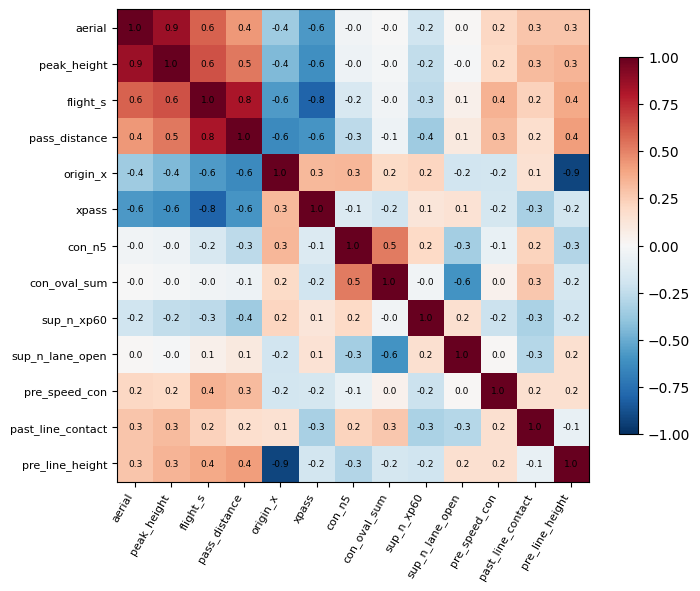

In [4]:
print('features:', model.FEATURES)
print('missing values per feature:', {k: int(v) for k, v in data[model.FEATURES].isna().sum().items() if v > 0})
cm = data[model.FEATURES].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.4, 6))
im = ax.imshow(cm, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns, fontsize=8)
for i in range(len(cm)):
    for j in range(len(cm)): ax.text(j, i, f'{cm.iloc[i, j]:.1f}', ha='center', va='center', fontsize=6.5)
plt.colorbar(im, shrink=.8); plt.tight_layout(); plt.show()

## 4. How good is it? (out-of-fold results)

Log loss and Brier score are better when lower; AUC is better when higher. The base rate model predicts everyone at the average retention. The calibration slope should be near 1 and the intercept near 0.

In [5]:
m = summary['metrics'].copy()
display(m.round(4))
print(f"calibration of the average: slope {summary['calibration_slope']:.2f}, intercept {summary['calibration_intercept']:.2f}")

,log_loss,brier,auc
logistic,0.5682,0.1915,0.7685
boosted trees,0.5739,0.1950,0.7564
average,0.5634,0.1905,0.7691
base rate,0.6750,0.2410,0.5000


calibration of the average: slope 1.03, intercept 0.02


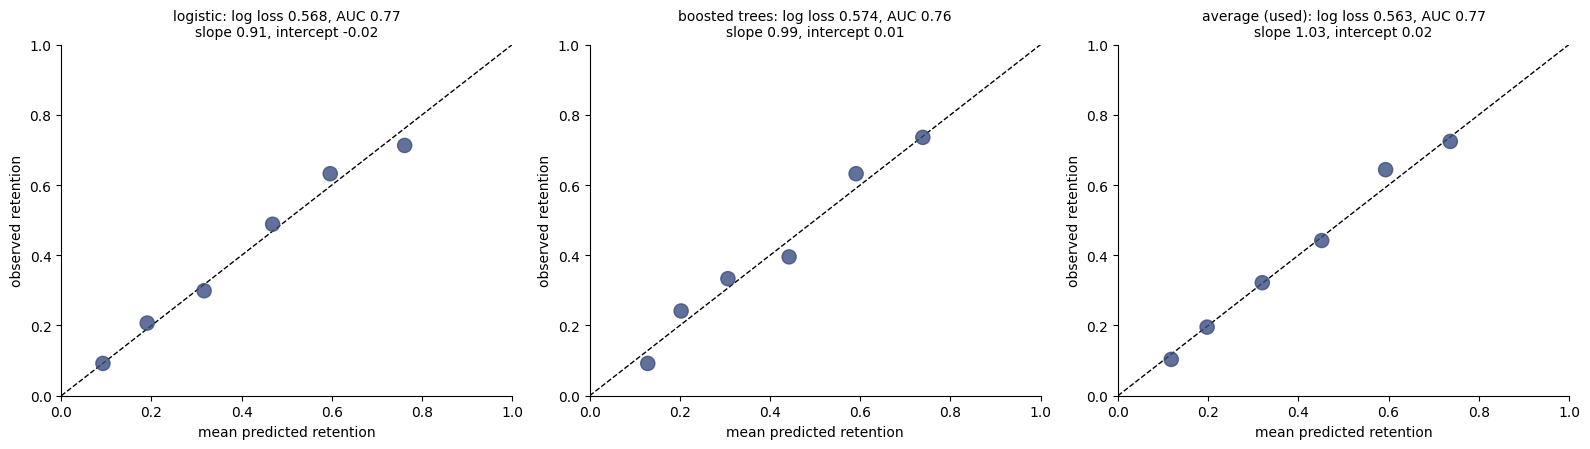

In [6]:
y = data.retained.astype(int).to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, p) in zip(axes, (('logistic', trained['logit']), ('boosted trees', trained['trees']), ('average (used)', trained['xr_contact']))):
    plot_calibration(ax, y, p, name)
plt.tight_layout(); plt.show()

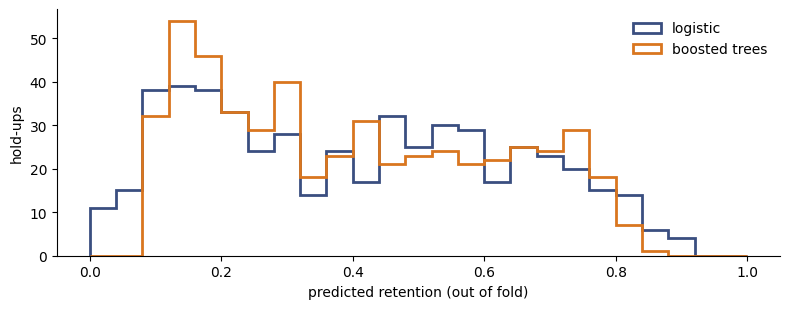

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for p, c, lab in ((trained['logit'], BLUE, 'logistic'), (trained['trees'], ORANGE, 'boosted trees')):
    ax.hist(p, bins=np.linspace(0, 1, 26), histtype='step', lw=2, color=c, label=lab)
ax.set_xlabel('predicted retention (out of fold)'); ax.set_ylabel('hold-ups'); ax.legend(frameon=False); clean_axes(ax)
plt.tight_layout(); plt.show()

## 5. What the model uses

**Logistic coefficients** (per standard deviation of the feature, with a 90% interval from re-fitting on matches drawn with replacement) say which features push retention up or down. **Boosted-tree gain** says how much each feature is used.

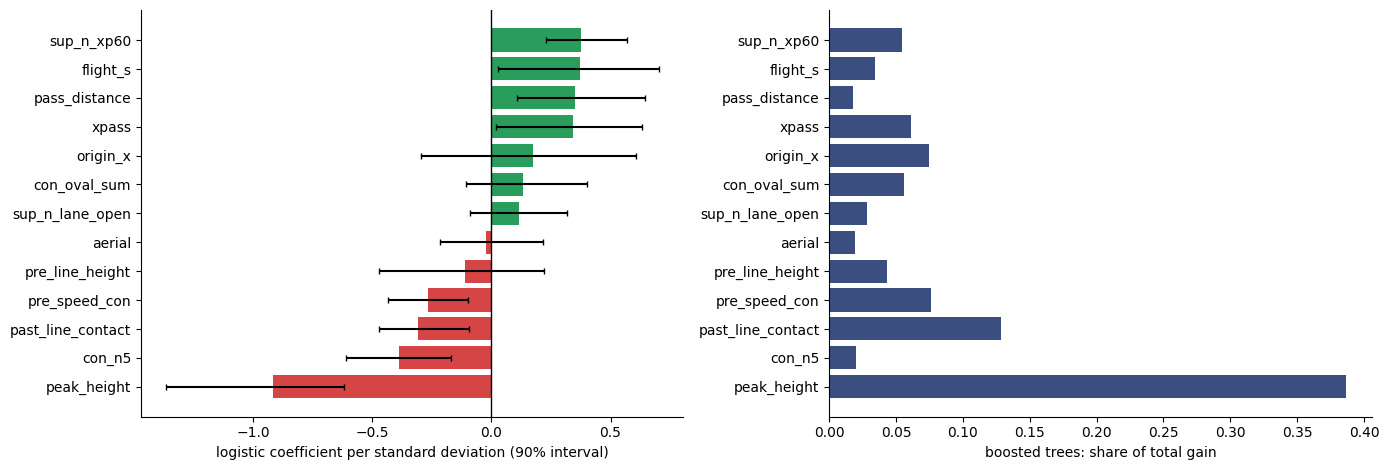

In [8]:
rng = np.random.default_rng(0)
match_ids = data.match_id.unique()
coefs = []
for _ in range(200):
    chosen = rng.choice(match_ids, len(match_ids), replace=True)
    sample = pd.concat([data[data.match_id == m_] for m_ in chosen])
    fit = model.make_logit().fit(sample[model.FEATURES], sample.retained.astype(int)); coefs.append(fit[-1].coef_[0])
coefs = np.array(coefs)
beta = model.make_logit().fit(data[model.FEATURES], y)[-1].coef_[0]
lo, hi = np.percentile(coefs, [5, 95], axis=0)
trees = model.make_trees().fit(data[model.FEATURES], y)
gain = pd.Series(trees.booster_.feature_importance('gain'), index=model.FEATURES); gain = gain / gain.sum()
order = np.argsort(beta); names = np.array(model.FEATURES)[order]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(range(len(beta)), beta[order], xerr=[beta[order] - lo[order], hi[order] - beta[order]], color=[RED if b < 0 else GREEN for b in beta[order]], ecolor='k', capsize=2)
ax[0].set_yticks(range(len(beta))); ax[0].set_yticklabels(names); ax[0].axvline(0, c='k', lw=1); ax[0].set_xlabel('logistic coefficient per standard deviation (90% interval)')
ax[1].barh(range(len(beta)), gain.loc[names].values, color=BLUE); ax[1].set_yticks(range(len(beta))); ax[1].set_yticklabels(names); ax[1].set_xlabel('boosted trees: share of total gain')
for a in ax: clean_axes(a)
plt.tight_layout(); plt.show()

## 6. Does each group of features earn its place?

The logistic model refitted (out of fold, same folds) with the groups added one at a time.

In [9]:
rows, used = [], []
for group, cols in model.FEATURE_GROUPS.items():
    used += cols
    p = model.cross_validated_predict(data[used], y, data.match_id.to_numpy(), model.make_logit, repeats=3)
    rows.append(dict(features_up_to=group, n_features=len(used), **model.score(y, p)))
pd.DataFrame(rows).set_index('features_up_to').round(4)

,n_features,log_loss,brier,auc
features_up_to,,,,
pass,6,0.6055,0.2078,0.7165
pressure,8,0.6010,0.2058,0.7180
support,10,0.5793,0.1963,0.7536
own state,13,0.5690,0.1918,0.7682


## 7. Set-up added and duel added

The same fitted models applied to the **release state** (pressure, support, speed and line position as they were when the ball was played) give xR at release. The change between release and contact is the set-up; what is left of the outcome is the duel.

The contributions below are exact for the logistic part: the change in log-odds between release and contact, split by feature and by group.

mean xR at release 0.409, at contact 0.403, observed 0.405
league mean set-up added (raw) -0.006: balls get a little harder between release and contact on average; scores are centred on it
53% of hold-ups get harder between release and contact; the middle 80% range from -0.14 to +0.11


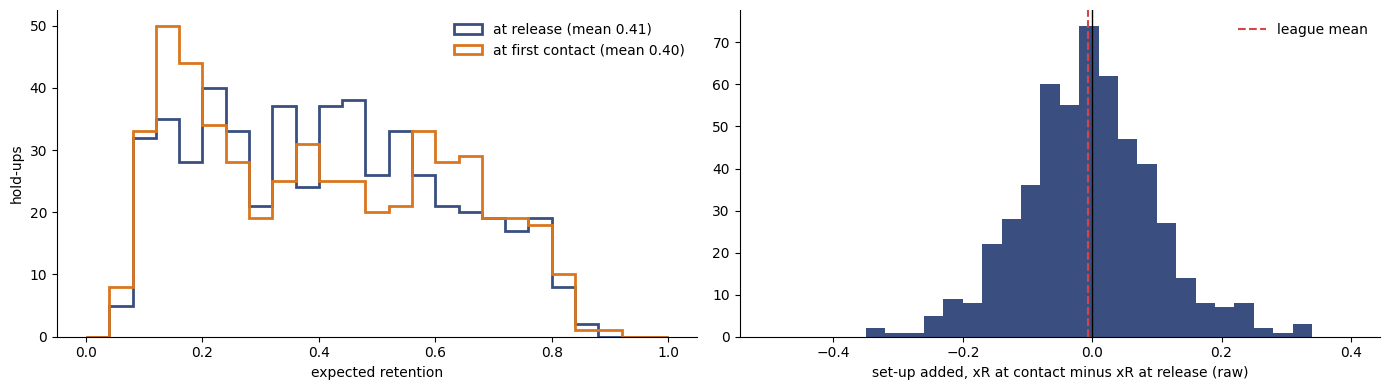

In [10]:
results = trained['results'].merge(data[['event_id', 'retained']], on='event_id').dropna(subset=['roe'])
print(f"mean xR at release {results.xr_release.mean():.3f}, at contact {results.xr_contact.mean():.3f}, observed {results.retained.mean():.3f}")
print(f"league mean set-up added (raw) {trained['summary']['league_setup_mean']:+.3f}: balls get a little harder between release and contact on average; scores are centred on it")
print(f"{(results.setup < 0).mean():.0%} of hold-ups get harder between release and contact; the middle 80% range from {results.setup.quantile(.1):+.2f} to {results.setup.quantile(.9):+.2f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(0, 1, 26)
ax[0].hist(results.xr_release, bins=bins, histtype='step', lw=2, color=BLUE, label=f'at release (mean {results.xr_release.mean():.2f})')
ax[0].hist(results.xr_contact, bins=bins, histtype='step', lw=2, color=ORANGE, label=f'at first contact (mean {results.xr_contact.mean():.2f})')
ax[0].set_xlabel('expected retention'); ax[0].set_ylabel('hold-ups'); ax[0].legend(frameon=False)
ax[1].hist(results.setup, bins=np.linspace(-.5, .4, 31), color=BLUE); ax[1].axvline(0, c='k', lw=1)
ax[1].axvline(trained['summary']['league_setup_mean'], c=RED, ls='--', label='league mean'); ax[1].set_xlabel('set-up added, xR at contact minus xR at release (raw)'); ax[1].legend(frameon=False)
for a in ax: clean_axes(a)
plt.tight_layout(); plt.show()

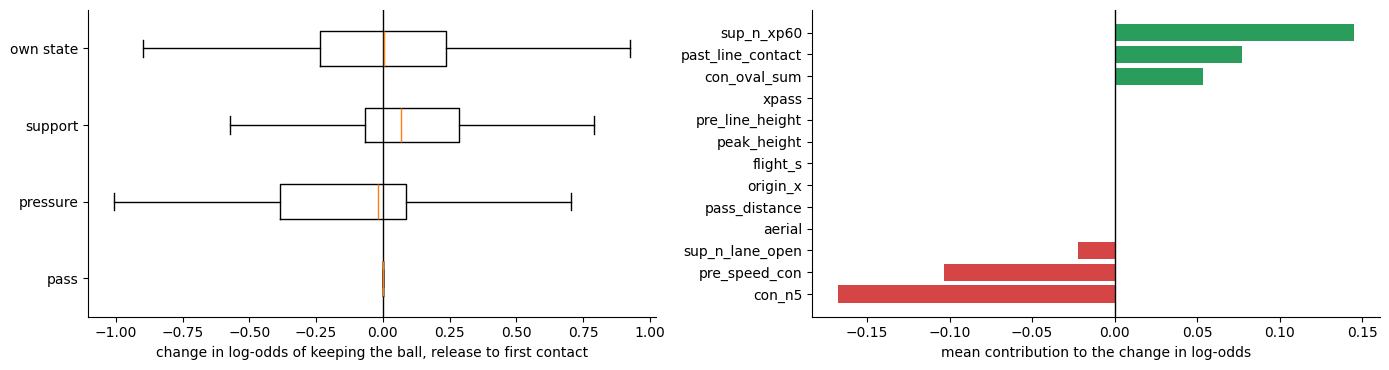

In [11]:
fit = model.make_logit().fit(data[model.FEATURES], y)
coef = fit[-1].coef_[0]
z_contact, z_release = fit[:-1].transform(data[model.FEATURES]), fit[:-1].transform(model.release_state(data))
contrib = pd.DataFrame((z_contact - z_release) * coef, columns=model.FEATURES)
by_group = pd.DataFrame({g: contrib[cols].sum(axis=1) for g, cols in model.FEATURE_GROUPS.items()})
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].boxplot([by_group[g] for g in by_group], labels=list(by_group), showfliers=False, vert=False); ax[0].axvline(0, c='k', lw=1)
ax[0].set_xlabel('change in log-odds of keeping the ball, release to first contact')
mean_c = contrib.mean().sort_values()
ax[1].barh(mean_c.index, mean_c.values, color=[RED if v < 0 else GREEN for v in mean_c.values]); ax[1].axvline(0, c='k', lw=1); ax[1].set_xlabel('mean contribution to the change in log-odds')
for a in ax: clean_axes(a)
plt.tight_layout(); plt.show()

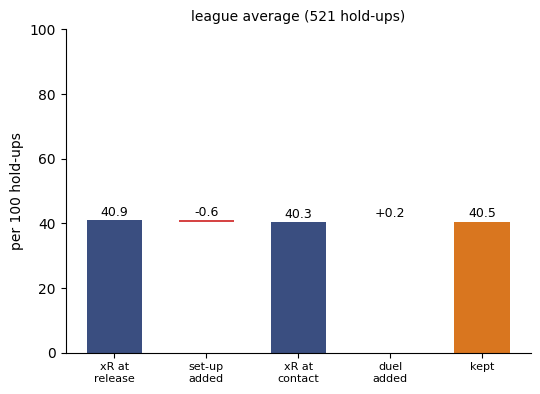

In [12]:
scored = data.merge(results[['event_id', 'xr_release', 'xr_contact', 'setup', 'duel']], on='event_id')
fig, ax = plt.subplots(figsize=(6, 4.2)); plot_waterfall(ax, scored.assign(retained=scored.retained), f'league average ({len(scored)} hold-ups)'); plt.show()

## 8. Expected value added (EPV)

Whether a hold-up is kept is not the only thing that matters: a kept ball that goes backwards is worth less than one that moves the attack forward. **Value added** is the change in SkillCorner's EPV from the moment he gets the ball to the next action. It depends heavily on where on the pitch he is, so a second model, a ridge regression averaged with boosted trees on the same features plus the starting EPV, predicts the value added of an average striker in the situation. **Value over expected (voe)** = value added - expected value added. It is trained and scored out of fold in the same way.

508 hold-ups with a value; out-of-fold R2 0.166; correlation 0.41; mean value added -2.64 points


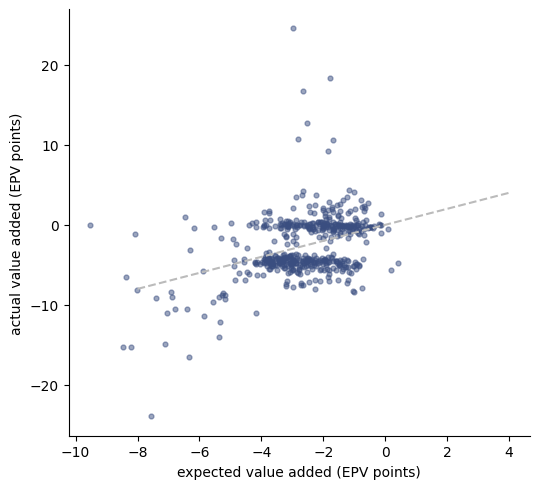

In [13]:
has = data.value_added.notna()
v = data[has]
expected = trained['expected_value'][has]
r2 = 1 - ((v.value_added - expected) ** 2).sum() / ((v.value_added - v.value_added.mean()) ** 2).sum()
print(f"{has.sum()} hold-ups with a value; out-of-fold R2 {r2:.3f}; correlation {np.corrcoef(v.value_added, expected)[0, 1]:.2f}; mean value added {v.value_added.mean() * 100:+.2f} points")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(expected * 100, v.value_added * 100, s=12, alpha=.5, c=BLUE); ax.plot([-8, 4], [-8, 4], c='#bbb', ls='--')
ax.set_xlabel('expected value added (EPV points)'); ax.set_ylabel('actual value added (EPV points)'); clean_axes(ax); plt.tight_layout(); plt.show()

## 9. The saved model

`data/models/holdup_model.joblib` holds everything the event pipeline needs to score a new match: the calibration of expected pass completion, the logistic and tree models for retention, the two expected-value models and the league mean set-up used for centring. The cell below reloads it and checks that it reproduces the scores for one training match (these are in-sample, so slightly better than the out-of-fold numbers used for the player stats).

In [14]:
saved = model.load_model(MODEL_PATH)
print('saved parts:', list(saved))
match_id = int(events.match_id.iloc[0])
ev = events[events.match_id == match_id].reset_index(drop=True); ft = features[features.event_id.isin(ev.event_id)].reset_index(drop=True)
from holdup.pipelines import score_events
again = score_events(ev, ft, saved)
print(f'match {match_id}: {len(again)} hold-ups scored; mean xR at release {again.xr_release.mean():.3f}, at contact {again.xr_contact.mean():.3f}')
again.round(3).head()

saved parts: ['features', 'logit', 'trees', 'value_ridge', 'value_trees', 'league_setup_mean', 'xpass_platt']
match 1874553: 21 hold-ups scored; mean xR at release 0.403, at contact 0.392


,event_id,xpass,xr_release,xr_contact,setup,setup_c,duel,roe,roe_c,exp_value,voe
0,1874553_001,0.832,0.689,0.775,0.086,0.092,-0.775,-0.689,-0.683,-0.013,-0.070
1,1874553_002,0.684,0.745,0.722,-0.024,-0.018,-0.722,-0.745,-0.740,-0.015,-0.067
2,1874553_003,0.795,0.349,0.399,0.050,0.056,0.601,0.651,0.657,-0.028,0.015
3,1874553_004,0.813,0.344,0.348,0.003,0.009,-0.348,-0.344,-0.338,-0.021,0.025
4,1874553_005,0.311,0.181,0.341,0.160,0.166,0.659,0.819,0.825,-0.025,0.023
